<div align="center" style="padding:40px 24px;background:linear-gradient(135deg,#0e1a2e 0%,#13223b 100%);border-radius:14px;border-bottom:5px solid #ffd43b;">
  <p style="margin:0;color:#6aaef0;font-family:monospace;font-weight:700;font-size:14px;letter-spacing:.16em;text-transform:uppercase;">The AI Learning Hub · Lesson 03 · Applied AI: unstructured data</p>
  <h1 style="margin:14px 0 6px;color:#f1f5fb;font-size:42px;">🎮 Challenge 2 · YOLO Live</h1>
  <p style="margin:0;color:#b4c2d8;font-size:18px;">🖼️ Images → 🎬 Video → 📷 Your webcam: what can a 5 MB detector see in real time, on a laptop CPU?</p>
</div>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/the-ai-learning-hub/03-applied-ai-projects/blob/main/02_computer_vision/03_challenge_yolo/Challenge_2_YOLO_Live.ipynb) [![Slides](https://img.shields.io/badge/slides-Lesson_03-ffd43b)](https://the-ai-learning-hub.github.io/03-applied-ai-projects/#challenge-2)

In notebook 04 our model looked at a whole photo and gave **one answer**: *cat* or *dog*. Real cameras (phones, cars, shop tills, wildlife traps) need more: **what** is in the picture, **where**, and **how many**, many times per second. That is **object detection**, and the most famous family of detectors is **YOLO** (*You Only Look Once*). Today you push it through three stages, each harder than the last: still **images**, a **video** with moving objects, and finally **your own webcam**, live.

## 🎯 Objectives
By the end of this challenge you will be able to:
- explain the difference between **classification** (one label) and **detection** (boxes + classes + confidences), and name the other YOLO tasks (**segmentation**, **pose**, OBB);
- choose a YOLO **size** (n, s, m, l, x) knowing the trade-off between **accuracy** (mAP) and **speed** (ms per image, FPS);
- see how the **confidence threshold** and the **input size** change what the model finds;
- follow objects through a video (**tracking**: IDs and trails) and turn detections into numbers: counts over time and a heatmap;
- run a detector **live** on your webcam and read its **FPS** and latency.

**📋 Prerequisites:** notebook [04 · Cats vs dogs](../02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) · **▶️ How to use:** *Run All* once (it uses the test photos and videos and replays a video instead of the webcam), then change the ✏️ **YOUR TURN** cells: your own photos, another model, and `LIVE = True` for the webcam. You play alone, on your own laptop.

## 🎮 How to play

> | Stage | What YOLO gets | Your mission |
> |---|---|---|
> | 🖼️ **1 · Images** | 8 test photos (street, table, desk, market, elephants, skatepark, parking lot, kangaroos) **+ yours** | Find the threshold where the boxes are "just right"; catch YOLO making a mistake |
> | 🎬 **2 · Video** | a 12-second traffic video (or a street full of people, or **your own video**) | Count the different cars with tracking; read the heatmap: where do objects go? |
> | 📷 **3 · Webcam** | **you**, live, for 30 seconds | Show YOLO as many different classes as you can, fool it with a photo on your phone, find the distance where it loses a cup |
>
> **Your own media** 📂 Copy photos (`.jpg`, `.png`) and videos (`.mp4`, `.mov`…) into the [`my_media/`](my_media/) folder: every stage picks them up automatically. In Colab, use the 📤 upload cell below.
>
> **Two rules:** 🔒 do not film or upload other people without their permission, and do not commit personal photos to git (the folder is ignored by git on purpose).

## 📑 Contents
1. [🧠 Meet YOLO: sizes, tasks and your model](#sec-1)
2. [🖼️ Stage 1 · Images](#sec-2)
3. [🎬 Stage 2 · Video](#sec-3)
4. [📷 Stage 3 · Webcam](#sec-4)
5. [🧠 What did we learn?](#sec-5)
6. [📌 Summary](#sec-6)
7. [📚 Learn more](#sec-7)

<a id="sec-0"></a>
## ⚙️ Setup
Uses the `ultralytics` package (installed with the project; Colab installs it here). The model weights (≈ 5–8 MB each) download once into `data/_cache/yolo/`; the two test videos (≈ 4 MB) download once into `data/yolo_media/`.

In [1]:
# ⚙️ Setup: works locally (VS Code / Jupyter) and in Google Colab
import os
import subprocess
import sys
import warnings
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path("/content/03-applied-ai-projects")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/the-ai-learning-hub/03-applied-ai-projects.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=True)
    os.chdir(ROOT)
else:  # locally: walk up until we find the folder that has src/ and data/
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(ROOT))

# Quieter output: no download bars or library chatter
warnings.filterwarnings("ignore")
os.environ.setdefault("YOLO_VERBOSE", "False")   # no ultralytics chatter (set before importing it)
print("Project root:", ROOT.name, "(Colab)" if IN_COLAB else "(local)")

Project root: 03-applied-ai-projects (local)


In [2]:
import time

import cv2
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from ultralytics import YOLO

from src import challenges as ch
from src.paths import cache_dir, data_dir
from src.plotting import apply_style

apply_style()
HERE = ROOT / "02_computer_vision" / "03_challenge_yolo"
MEDIA = HERE / "media"                             # 8 test photos (open licences: see the README)
MY_MEDIA = HERE / "my_media"                       # 👉 put YOUR photos and videos here
VIDEOS = data_dir("yolo_media") / "yolo_media"     # 2 test videos, downloaded once
WEIGHTS = cache_dir() / "yolo"                     # model weights, downloaded once (not into the repository)
WEIGHTS.mkdir(parents=True, exist_ok=True)

# Only the authors use this (EXPORT_SLIDES=1) to refresh the images in the slide deck.
EXPORT_SLIDES = os.environ.get("EXPORT_SLIDES") == "1"
def save_slide(fig, name):
    if EXPORT_SLIDES:
        from src.vision import save_slide_image
        save_slide_image(fig, ROOT / "assets" / "slides" / name)


test_images, _ = ch.list_media(MEDIA)
_, test_videos = ch.list_media(VIDEOS)
my_images, my_videos = ch.list_media(MY_MEDIA)
print(f"Test media: {len(test_images)} photos, {len(test_videos)} videos ({', '.join(v.name for v in test_videos)})")
print(f"Your media in my_media/: {len(my_images)} photos, {len(my_videos)} videos")

Test media: 8 photos, 2 videos (pedestrians_madrid.mp4, traffic_chiang_mai.mp4)
Your media in my_media/: 0 photos, 0 videos


**📤 Your own photos and videos.** Locally, simply copy them into [`my_media/`](my_media/) and re-run the cell above. In Colab, set `UPLOAD = True` and run this cell (then re-run the cell above).

> 🔒 **Privacy in Colab:** an upload is **sent to Google's hosted runtime** and saved there in `my_media/` (it disappears when the runtime ends; delete it earlier from the 📁 Files panel if you like).

In [3]:
UPLOAD = False      # 👉 Colab: True = upload photos/videos from your computer or phone

if UPLOAD and IN_COLAB:
    from google.colab import files
    for name, content in (files.upload() or {}).items():
        (MY_MEDIA / Path(name).name).write_bytes(content)
        print("saved", name)
elif UPLOAD:
    print(f"Locally there is nothing to upload: copy your files into {MY_MEDIA.relative_to(ROOT)}")
else:
    print("Upload skipped (UPLOAD = False).")

Upload skipped (UPLOAD = False).


<a id="sec-1"></a>
# 1. 🧠 Meet YOLO: sizes, tasks and your model

> 🧠 **How it works, in plain words**
> - **Classification** (notebook 04): one photo in → **one label** out (*"dog, 97%"*). It does not say where the dog is, or that there is also a plant.
> - **Detection**: one photo in → a **list of objects**, each with a **box** (where), a **class** (what) and a **confidence** (how sure).
> - **YOLO** (*You Only Look Once*, Redmon et al. 2016) looks at the whole image **once**: a CNN like the ones of notebooks 03–04 turns the image into a grid of features, and every grid cell proposes boxes and classes at the same time. One pass = fast enough for live video.
> - **Analogy:** classification is a person who glances at a photo and says *"it's a kitchen"*; detection is a person who points at each thing and says *"cup here, bottle there, laptop there"*.
> - **Limits:** the pretrained models know the **80 classes** of the COCO dataset (no *pen*, no *glasses*, no *kangaroo*), small or hidden objects are hard, and they only see pixels.

> 📖 **Mini-glossary**
> - **Bounding box:** the rectangle around an object, 4 numbers (x1, y1, x2, y2) in pixels.
> - **Confidence:** the model's score for a box (0–1). We keep boxes above a **threshold**, the same idea as the threshold of Lesson 02.
> - **mAP 50-95:** the standard accuracy score of detectors (0–100): it rewards the right class **and** a well-placed box. Higher is better.
> - **Latency / FPS:** milliseconds per image / images per second. Video feels smooth above ~15 FPS.

**One family, five sizes.** The official documentation is at **[docs.ultralytics.com](https://docs.ultralytics.com/)**. Each YOLO version (YOLOv8, YOLO11, **YOLO26**…) comes in five sizes, from *nano* to *extra-large*: the bigger the model, the more it sees, and the slower it runs. The numbers below are copied from the [YOLO26 page](https://docs.ultralytics.com/models/yolo26/) (COCO, 640-pixel images; CPU = ONNX on a server CPU, T4 = a data-centre GPU).

In [4]:
sizes = pd.DataFrame(ch.YOLO26_SIZES).set_index("model")
sizes["FPS on CPU (≈)"] = (1000 / sizes["CPU ms"]).round(0).astype(int)
display(sizes)
display(pd.DataFrame(ch.YOLO_TASKS).set_index("task"))

,size,params (M),mAP 50-95,CPU ms,T4 GPU ms,FPS on CPU (≈)
model,,,,,,
yolo26n.pt,nano,2.4,40.9,38.9,1.7,26
yolo26s.pt,small,9.5,48.6,87.2,2.5,11
yolo26m.pt,medium,20.4,53.1,220.0,4.7,5
yolo26l.pt,large,24.8,55.0,286.2,6.2,3
yolo26x.pt,extra-large,55.7,57.5,525.8,11.8,2


,weights,output
task,,
detect,yolo26n.pt,boxes + class + confidence
segment,yolo26n-seg.pt,boxes + a pixel mask per object
pose,yolo26n-pose.pt,people + 17 body keypoints (skeleton)
obb,yolo26n-obb.pt,"rotated boxes (aerial photos: ships, planes)"
classify,yolo26n-cls.pt,one label for the whole image (like notebook 04)


👀 **What to notice:** from **n** to **x** the accuracy goes up from 40.9 to 57.5 mAP, but the model is **23× bigger** and **13× slower** on a CPU. On a laptop, *nano* is the only size that runs live; on a GPU even *x* does. Same story as the CPU vs GPU race of notebook 04. And the same family also does **segmentation** (a mask per object), **pose** (a skeleton per person), **OBB** (rotated boxes for aerial photos) and **classification**: just a different file name.

## ✏️ YOUR TURN · choose your model
Run it once as it is. Then try `"yolo26s.pt"` (more accurate, ≈ 2× slower) and re-run the stages: does it find more objects? Is the webcam still smooth? (You can also try another version, e.g. `"yolo11n.pt"`.)

In [5]:
# ✏️ YOUR TURN
MODEL = "yolo26n.pt"         # 👉 "yolo26n.pt" (nano, fastest) · "yolo26s.pt" (small) · "yolo26m.pt" (medium, slow on a CPU)
MIN_CONFIDENCE = 0.3         # boxes below this confidence are hidden (try 0.15 and 0.6)

model = YOLO(str(WEIGHTS / MODEL))                 # downloads once into data/_cache/yolo/
NAME = MODEL.removesuffix(".pt")                  # e.g. "yolo26n", for titles


def detect(frame, conf=MIN_CONFIDENCE, imgsz=640):
    """YOLO on one image (a file path or a BGR array from OpenCV) → [(class, confidence, (x1, y1, x2, y2)), ...]."""
    return ch.detections_from_result(model.predict(frame, conf=conf, imgsz=imgsz, device="cpu", verbose=False)[0])


warm = cv2.imread(str(MEDIA / "desk.jpg"))
detect(warm)                                        # warm-up: the very first prediction is slower
t0 = time.perf_counter()
for _ in range(5):
    dets = detect(warm)
ms = (time.perf_counter() - t0) / 5 * 1000
print(f"{NAME}: {sum(p.numel() for p in model.model.parameters()) / 1e6:.1f} M parameters, "
      f"{len(model.names)} classes, {ms:.0f} ms per photo on this CPU (≈ {1000 / ms:.0f} images per second)")
display(pd.DataFrame([(c, round(p, 2), *[round(v) for v in b]) for c, p, b in dets],
                     columns=["class", "confidence", "x1", "y1", "x2", "y2"]))
print("The 80 classes it knows:", ", ".join(model.names.values()))

yolo26n: 2.6 M parameters, 80 classes, 35 ms per photo on this CPU (≈ 29 images per second)


,class,confidence,x1,y1,x2,y2
0,keyboard,0.91,690,579,1123,814
1,tv,0.86,24,0,933,620
2,mouse,0.85,1108,487,1268,545
3,cell phone,0.62,399,653,504,752


The 80 classes it knows: person, bicycle, car, motorcycle, airplane, bus, train, truck, boat, traffic light, fire hydrant, stop sign, parking meter, bench, bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe, backpack, umbrella, handbag, tie, suitcase, frisbee, skis, snowboard, sports ball, kite, baseball bat, baseball glove, skateboard, surfboard, tennis racket, bottle, wine glass, cup, fork, knife, spoon, bowl, banana, apple, sandwich, orange, broccoli, carrot, hot dog, pizza, donut, cake, chair, couch, potted plant, bed, dining table, toilet, tv, laptop, mouse, remote, keyboard, cell phone, microwave, oven, toaster, sink, refrigerator, book, clock, vase, scissors, teddy bear, hair drier, toothbrush


That table **is** the detector's answer for the desk photo: one row per object. Everything that follows (boxes, counts, tracks, heatmaps) is drawn from rows like these.

<a id="sec-2"></a>
# 2. 🖼️ Stage 1 · Images

All the test photos (and yours, from `my_media/`), one prediction each. Every class gets its own colour; the panel in the corner counts the objects.

8 photos in 0.5 s on this CPU


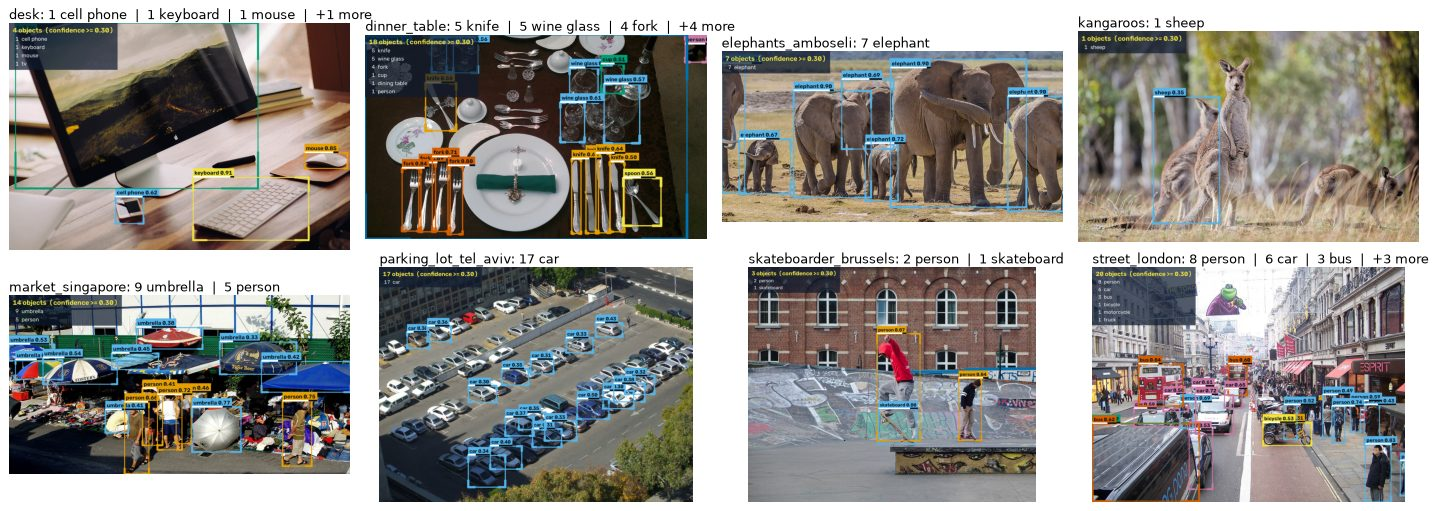

In [6]:
photos = test_images + my_images
annotated, titles = [], []
t0 = time.perf_counter()
for path in photos:
    frame = cv2.imread(str(path))
    found = detect(frame)
    annotated.append(ch.draw_detections(frame, found, MIN_CONFIDENCE))
    titles.append(f"{path.stem}: {ch.counts_text(ch.count_classes(found), 3)}")
print(f"{len(photos)} photos in {time.perf_counter() - t0:.1f} s on this CPU")
fig = ch.plot_media_grid(annotated, titles, ncols=4)
save_slide(fig, "ch2-gallery.webp")
ch.show_fig(fig)

👀 **What to notice:** 7 elephants, 17 cars, 5 knives and 5 wine glasses: detection **counts**. But look at the **kangaroos**: YOLO calls one a *sheep*, because *kangaroo* is not one of its 80 classes, so it picks the closest thing it knows. And the iMac on the desk is a *tv*: same reason.

## 🔢 Count the objects
A crowded table: every box YOLO proposed, its confidence, and how many objects of each class survive the threshold. Change `PHOTO` to one of yours (e.g. `MY_MEDIA / "my_photo.jpg"`).

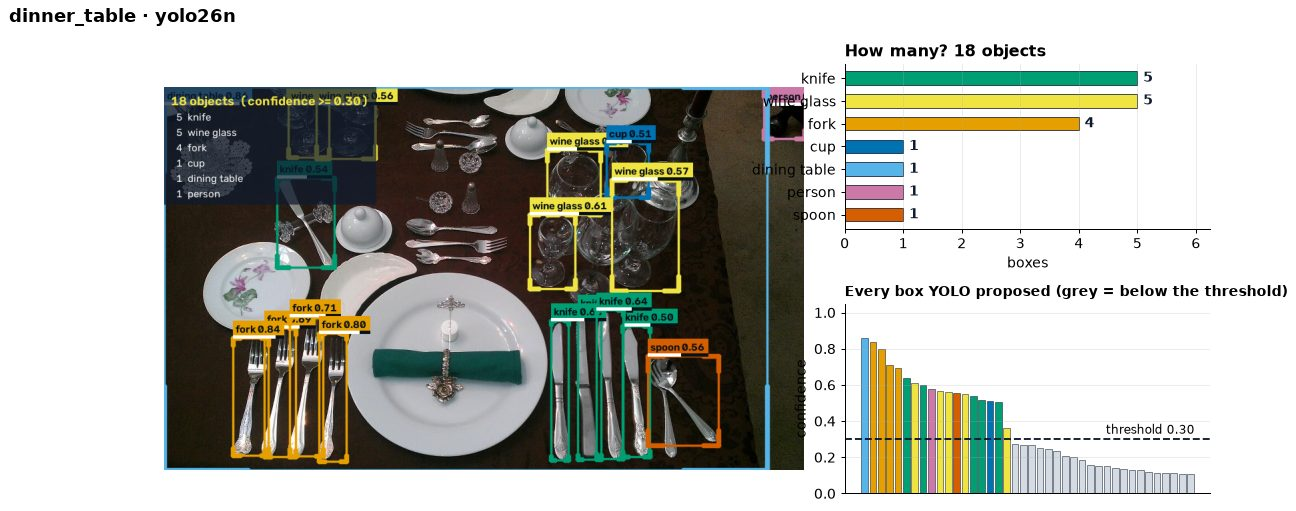

In [7]:
PHOTO = MEDIA / "dinner_table.jpg"          # ✏️ try "street_london.jpg", "market_singapore.jpg" or your own photo
frame = cv2.imread(str(PHOTO))
all_boxes = detect(frame, conf=0.05)        # one prediction with a very low threshold: we filter afterwards
ch.show_fig(ch.plot_detection_dashboard(frame, all_boxes, MIN_CONFIDENCE, title=f"{PHOTO.stem} · {NAME}"))

## 🎚️ The threshold slider
The threshold decides which boxes you **believe**. Low: you find everything, plus false alarms. High: only sure objects, but you miss some. Here is the same photo at three thresholds, then a live **slider** (drag it: the boxes appear and disappear instantly, because we only filter the boxes of one prediction).

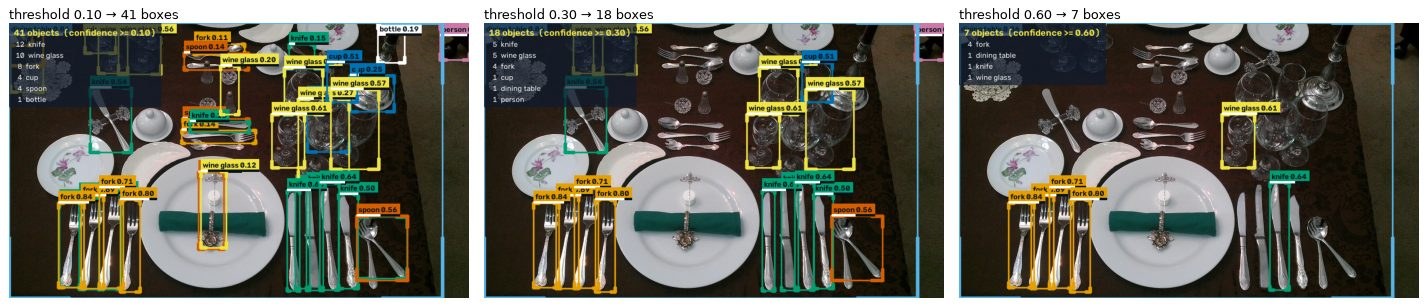

In [8]:
ch.show_fig(ch.plot_threshold_strip(frame, all_boxes, thresholds=(0.1, 0.3, 0.6)))
display(ch.threshold_explorer(frame, all_boxes, value=MIN_CONFIDENCE))   # 🎚️ drag me (needs a live kernel)

## 🦴 One photo, three tasks: boxes, masks, skeletons
Same photo, three models of the same family: **detect** (boxes), **segment** (the exact pixels of each object) and **pose** (17 keypoints per person: nose, shoulders, elbows, knees…). Two small extra downloads (≈ 7 and 8 MB).

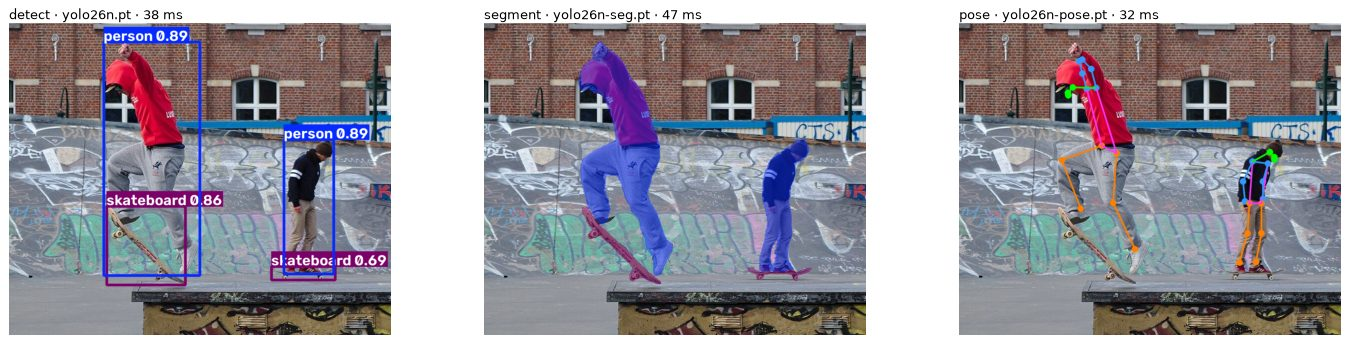

In [9]:
TRIO = MEDIA / "skateboarder_brussels.jpg"         # ✏️ try "street_london.jpg" (look closely at the poster!)
ZOOM = (0.30, 0.25, 0.90, 0.85)                    # part of the photo to keep (left, top, right, bottom); None = all
trio = cv2.imread(str(TRIO))
if ZOOM:
    h, w = trio.shape[:2]
    trio = trio[int(ZOOM[1] * h):int(ZOOM[3] * h), int(ZOOM[0] * w):int(ZOOM[2] * w)]
panels, titles = [], []
for task, weights in [("detect", MODEL), ("segment", "yolo26n-seg.pt"), ("pose", "yolo26n-pose.pt")]:
    m = model if task == "detect" else YOLO(str(WEIGHTS / weights))
    m.predict(trio, device="cpu", verbose=False)                      # warm-up
    t0 = time.perf_counter()
    r = m.predict(trio, conf=MIN_CONFIDENCE, device="cpu", verbose=False)[0]
    ms = (time.perf_counter() - t0) * 1000
    panels.append(r.plot(line_width=3, boxes=task == "detect", kpt_radius=6))
    titles.append(f"{task} · {weights} · {ms:.0f} ms")
ch.show_fig(ch.plot_media_grid(panels, titles, ncols=3))

👀 **What to notice:** the mask follows the skateboarder's legs and the board; the skeleton shows **how** he is standing. That is what fitness apps, sign-language research and football analytics use. All three run in a few tens of milliseconds on a CPU.

## 🙈 What YOLO gets wrong
Two classic failures. **(1) Unknown classes:** a kangaroo is not in COCO. **(2) Tiny objects:** YOLO shrinks every image to 640 pixels before looking; the cars in an aerial photo become a few pixels wide. Give it a bigger input (`imgsz=1280`) and count again.

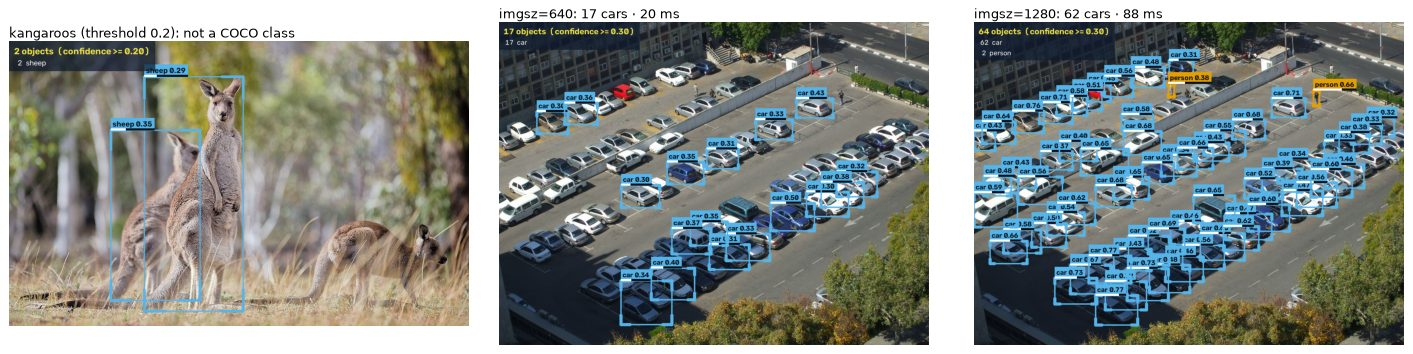

In [10]:
roo = cv2.imread(str(MEDIA / "kangaroos.jpg"))
park = cv2.imread(str(MEDIA / "parking_lot_tel_aviv.jpg"))
panels, titles = [ch.draw_detections(roo, detect(roo, conf=0.2), 0.2)], ["kangaroos (threshold 0.2): not a COCO class"]
for size in (640, 1280):
    t0 = time.perf_counter()
    found = detect(park, imgsz=size)
    ms = (time.perf_counter() - t0) * 1000
    panels.append(ch.draw_detections(park, found, MIN_CONFIDENCE))
    titles.append(f"imgsz={size}: {ch.count_classes(found).get('car', 0)} cars · {ms:.0f} ms")
ch.show_fig(ch.plot_media_grid(panels, titles, ncols=3))

👀 **What to notice:** at 640 pixels YOLO finds only a fraction of the cars; at 1280 it finds several times more, for a little more time. **Input size** is a knob, like the threshold: more pixels = small objects become visible, but every frame costs more. For live video we stay at 640.

<a id="sec-3"></a>
# 3. 🎬 Stage 2 · Video

A video is just many photos in a row (25–30 per second). Detecting each frame is not enough: to **count** cars we must know that the car in frame 10 is the **same** car as in frame 9. That is **tracking**:

> 🧠 **Tracking, in plain words:** for each new box, look for the box of the same class in the previous frame that overlaps it most (their **IoU**, *intersection over union*). If it overlaps enough, it keeps the old **ID** (`car #12`); if not, it gets a new one. Remember the centre of each box and you get its **trail**. Real trackers (ByteTrack, BoT-SORT, inside `model.track`) also predict where each object will move next; ours is a 40-line version in `src/challenges.py` so you can read it.

Every frame below is: YOLO → tracker → drawing (boxes, IDs, trails, a HUD with the counts and the **FPS meter**).

In [11]:
# ✏️ YOUR TURN: pick a video
VIDEO = VIDEOS / "traffic_chiang_mai.mp4"   # 👉 or VIDEOS / "pedestrians_madrid.mp4", or yours: my_videos[0]
MAX_SECONDS = 12                            # long videos: only the first seconds (a laptop CPU does ≈ 20–40 frames per second)

info = ch.video_info(VIDEO)
print(f"{VIDEO.name}: {info['width']}×{info['height']}, {info['fps']:g} frames per second, {info['seconds']} s")
video = ch.run_stream(detect, ch.video_frames(VIDEO, width=960, max_seconds=MAX_SECONDS), MIN_CONFIDENCE,
                      title=f"{NAME} | {VIDEO.stem}")
print(f"{video['frames']} frames in {video['frames'] / video['fps']:.1f} s → {video['fps']:.1f} FPS on this CPU "
      f"(YOLO alone: {np.mean(video['latency_ms']):.0f} ms per frame)")
display(HTML(ch.clip_html(video["kept"], info["fps"] / video["keep_every"], cache_dir() / "yolo" / "clips")))

traffic_chiang_mai.mp4: 1280×720, 25 frames per second, 12.0 s


300 frames in 10.8 s → 27.9 FPS on this CPU (YOLO alone: 20 ms per frame)


▶️ The replay above is the annotated video (every second frame, made smaller to keep the notebook light). Now the numbers behind it: **where** objects appeared (a heatmap: each box adds a bit of heat at its centre) and **how many** of each class were in the frame, second by second. The legend counts the **different** objects the tracker followed for at least 5 frames.

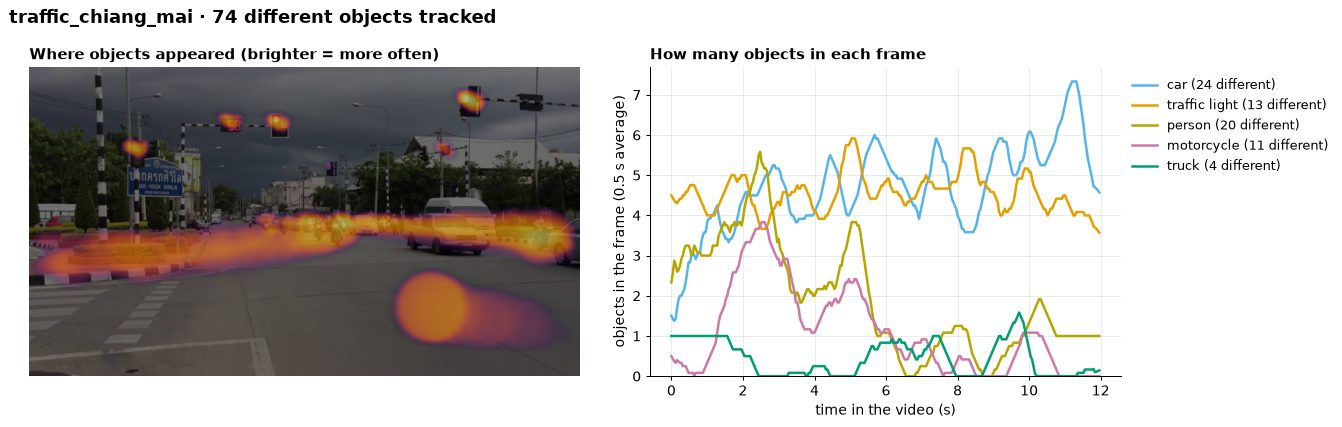

,car,person,traffic light,motorcycle,truck,bicycle,bus
different objects (tracks),24,20,13,11,4,1,1


In [12]:
fig = ch.plot_video_report(video, title=f"{VIDEO.stem} · {sum(video['unique'].values())} different objects tracked")
ch.show_fig(fig)
display(pd.Series(video["unique"], name="different objects (tracks)").to_frame().T)

👀 **What to notice:** the heatmap draws the **lanes** and the traffic lights by itself: nobody told the model where the road is. The count over time goes up and down as vehicles enter and leave. And look at the number of *different* cars: it is probably **too high**. When YOLO misses a car for a few frames or the box jumps, our simple tracker gives it a **new ID**. Counting is harder than detecting; that is why real traffic counters use better trackers and a "counting line".

<a id="sec-4"></a>
# 4. 📷 Stage 3 · Webcam (the finale)

The webcam uses the same loop as the video: capture a frame, detect objects, follow them across frames, and draw the boxes and track IDs. The FPS meter shows how quickly your computer can keep up.

**Settings:**
- `LIVE = True` uses your webcam. **Locally** an OpenCV window opens (click it and press **Q** to stop), or use `DISPLAY = "inline"` to watch inside the notebook (stop with ⏹ *Interrupt*). **In Colab** the webcam runs in your browser (allow the camera) and frames travel to Colab and back, so expect only a few FPS.
- `LIVE = False` (the default, so the notebook always runs) **replays** the street video *as if* it were a webcam.
- Wrong camera? Try `CAMERA_INDEX = 1`. No camera at all? It falls back to the replay by itself.

> 🔒 **Privacy:** in **local** live mode the frames stay in your laptop's memory (nothing is saved or uploaded). In **Colab** each frame is sent to Google's runtime to be processed (not saved). Please do not film other people without asking.

In [13]:
# ✏️ YOUR TURN
LIVE = False                 # 👉 True = your webcam
DISPLAY = "window"           # local only: "window" (press Q to stop) or "inline" (inside the notebook)
CAMERA_INDEX = 0             # 0 = built-in webcam; try 1 for an external camera
SECONDS = 30                 # length of the live run

In [14]:
source = None
if LIVE and IN_COLAB:
    cam = ch.ColabWebcam(width=640, max_seconds=SECONDS)
    try:
        live = ch.run_stream(detect, cam.frames(), MIN_CONFIDENCE, f"{NAME} | LIVE", display=cam.show, time_limit=SECONDS)
        source = "your webcam (Colab, through the browser)"
    except RuntimeError as err:
        print(f"📷 {err}")
elif LIVE:
    detect(np.zeros((480, 640, 3), np.uint8))                    # warm-up before the clock starts
    show, close = ch.local_display(DISPLAY)
    try:
        live = ch.run_stream(detect, ch.webcam_frames(CAMERA_INDEX), MIN_CONFIDENCE, f"{NAME} | LIVE | Q = stop",
                             display=show, time_limit=SECONDS)
        source = "your webcam"
    except RuntimeError as err:
        print(f"📷 {err}")
    finally:
        close()
if source is None:                                                # LIVE = False (or no camera): the replay
    REPLAY = VIDEOS / "pedestrians_madrid.mp4"
    live = ch.run_stream(detect, ch.video_frames(REPLAY, width=640, max_seconds=SECONDS), MIN_CONFIDENCE,
                         f"{NAME} | REPLAY (LIVE = False)")
    source = f"replay of {REPLAY.name} (set LIVE = True for your webcam)"
print(f"Source: {source}")
print(f"{live['frames']} frames · {live['fps'] or 0:.1f} FPS · YOLO {np.mean(live['latency_ms'] or [0]):.0f} ms per frame "
      f"(slowest {max(live['latency_ms'] or [0]):.0f} ms) · {len(live['discovered'])} different classes seen")

Source: replay of pedestrians_madrid.mp4 (set LIVE = True for your webcam)
288 frames · 42.6 FPS · YOLO 18 ms per frame (slowest 30 ms) · 6 different classes seen


**Your run, in three moments** (start, middle, end), and the classes YOLO saw, with the second each one first appeared. A strange class in the list (a *horse* in a shopping street?) is a false alarm: one confident frame is enough to add it. That is why the video stage counts objects only after 5 tracked frames.

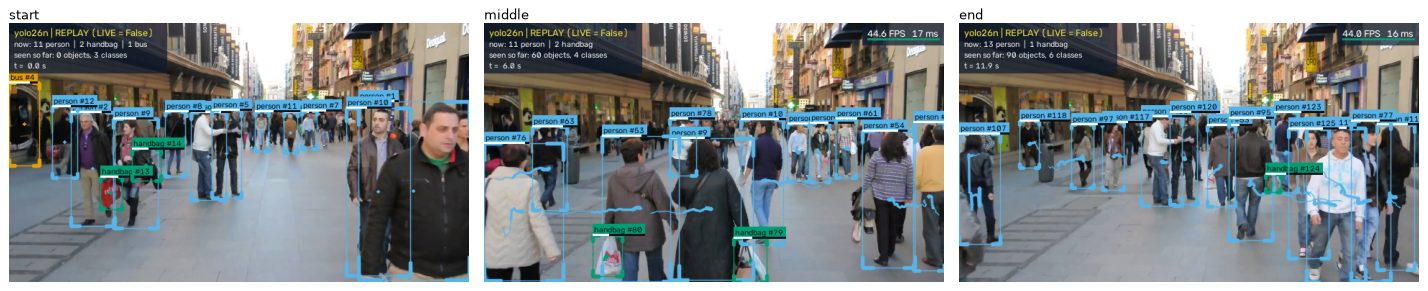

,0,1,2,3,4,5
class,person,handbag,bus,suitcase,horse,backpack
first seen (s),0.0,0.0,0.0,1.4,8.0,9.4


In [15]:
kept = live["kept"]
if kept:
    moments = [kept[0], kept[len(kept) // 2], kept[-1]]
    ch.show_fig(ch.plot_media_grid([m[..., ::-1] for m in moments], ["start", "middle", "end"], ncols=3))
discovered = pd.DataFrame(sorted(live["discovered"].items(), key=lambda kv: kv[1]),
                          columns=["class", "first seen (s)"])
display(discovered.T if len(discovered) else "Nothing detected: is the camera covered?")

<a id="sec-5"></a>
# 5. 🧠 What did we learn?

| What happened | The idea behind it | Back to |
|---|---|---|
| YOLO named **every** object, with a box | **detection** = many (box, class, confidence) per image; **classification** = one label per image | notebook 04 |
| The kangaroo became a *sheep*, the iMac a *tv* | a model only knows the classes of its training data (80 COCO classes) and always picks the closest one | Lesson 02 · data defines the task |
| Boxes appeared and disappeared with the slider | the **threshold** trades missed objects (recall) against false alarms (precision) | Lesson 02 · threshold tuning |
| 17 cars at 640 px, many more at 1280 px | small objects need more input pixels; bigger inputs cost time | notebook 03 · image size |
| Same family: boxes, masks, skeletons | one backbone, different **heads** and labels (detect, segment, pose, OBB, classify) | notebook 04 · transfer learning |
| `car #12` kept its ID; the count of cars was too high | **tracking** links detections across frames; simple IoU matching breaks when a box is missed | this challenge |
| ≈ 20–40 **FPS** with *nano*, much less with bigger models | accuracy vs speed: choose the size for the hardware (CPU, phone, GPU) | notebook 04 · CPU vs GPU race |

## 💬 Discussion
1. A self-driving car uses detection. Would you rather lower or raise the confidence threshold for *person*? What does each error cost?
2. A shop wants to count customers with a camera at the door. Which of today's problems (ID switches, tiny objects, people hidden behind others) would make the count wrong, and which way (too high or too low)?
3. Your phone-screen trick fooled YOLO (or not). Is that a bug of the model or a limit of what it was asked to learn?
4. Locally the webcam frames never left your laptop; in Colab they travelled to a cloud runtime. Why does that difference matter for a real product with a camera?

<details>
<summary>🧑‍🏫 Instructor guide</summary>

1. Lower: missing a pedestrian (false negative) is far worse than braking for a shadow (false positive). Same reasoning as the spam filter and the threshold of Lesson 02: **the cost of each error** chooses the threshold, not the model. Real systems also combine several sensors and frames (tracking is part of that).
2. ID switches (a person missed for a few frames gets a new ID) push the count **up**; people hidden behind others and small people far away push it **down**. Real counters use a better tracker (motion model, appearance features), a **counting line** at the door (count only crossings), and a camera placed above the door (no occlusion). Point at the "too many different cars" result of Stage 2.
3. A limit of the task: COCO labels say "there is a car in these pixels", never "this car is real". To tell a real object from a screen you need other data (depth, motion over time) and other labels. Link to adversarial examples (Challenge 1) and the AI-generated dog of notebook 04.
4. Privacy and consent: camera images are personal data. Processing on the device (nothing leaves the laptop, nothing is saved) is a strong design choice; the Colab path sends every frame to Google's servers. Mention data minimisation and where data is processed (GDPR), and the rule of not filming other people.
</details>

<a id="sec-6"></a>
# 6. 📌 Summary

| Idea | In one line |
|---|---|
| Detection | One image → many boxes, each with a class and a confidence |
| YOLO | Looks at the image once (one CNN pass): fast enough for live video on a CPU |
| Sizes n → x | More parameters = higher mAP but slower; *nano* for CPUs and phones |
| Tasks | Same family: detect, segment (masks), pose (skeletons), OBB, classify |
| Threshold and input size | Two knobs: false alarms vs missed objects; small objects vs speed |
| COCO classes | A detector only knows what it was trained on (80 everyday classes) |
| Tracking | Link boxes frame to frame (IoU) → IDs, trails, counts, heatmaps |
| FPS / latency | The speed that matters for video and webcams |

**✅ Checklist:**
- [ ] I can explain classification vs detection vs segmentation vs pose with an example.
- [ ] I ran YOLO on my own photo or video (in `my_media/`).
- [ ] I know what happens when I move the threshold, and when I change `imgsz`.
- [ ] I can say why the tracker counted too many cars.
- [ ] I played the webcam stage (or the replay) and read the FPS meter.

<a id="sec-7"></a>
# 7. 📚 Learn more

> 📚 **Learn more**
> - Ultralytics documentation: [docs.ultralytics.com](https://docs.ultralytics.com/) · [YOLO26](https://docs.ultralytics.com/models/yolo26/) · [Predict mode and the `Results` object](https://docs.ultralytics.com/modes/predict/) · [Track mode (`model.track`)](https://docs.ultralytics.com/modes/track/) · [Tasks: detect, segment, pose, OBB, classify](https://docs.ultralytics.com/tasks/). ⚖️ **Licence:** the `ultralytics` package and its YOLO weights are under **AGPL-3.0** (free for learning and open-source projects; a commercial product that uses them must either publish its source code or buy an Ultralytics Enterprise licence).
> - Redmon, Divvala, Girshick & Farhadi (2016). [*You Only Look Once: Unified, Real-Time Object Detection*](https://arxiv.org/abs/1506.02640), the original YOLO paper.
> - Lin et al. (2014). [*Microsoft COCO: Common Objects in Context*](https://cocodataset.org/), the dataset behind the 80 classes.
> - Zhang et al. (2022). [*ByteTrack: Multi-Object Tracking by Associating Every Detection Box*](https://arxiv.org/abs/2110.06864), one of the trackers behind `model.track`.
> - Thys, Van Ranst & Goedemé (2019). [*Fooling automated surveillance cameras: adversarial patches to attack person detection*](https://arxiv.org/abs/1904.08653): a printed patch that makes people invisible to YOLO.
> - The test photos and videos come from Wikimedia Commons under open licences: authors and licences in the [README](README.md#credits).

---
<div align="center">

⬅️ [Previous: 04 · Cats vs dogs, and our pets](../02_project_cats_vs_dogs/04_Cats_vs_Dogs_And_Our_Pets.ipynb) &nbsp;·&nbsp; 🏠 [Lesson 03](../../README.md) &nbsp;·&nbsp; [Next: 05 · Everything is a vector](../../03_multimodal/01_project_everything_is_a_vector/05_Everything_Is_A_Vector.ipynb) ➡️

**The AI Learning Hub** · Lesson 03 — Applied AI: unstructured data<br>
MIT License

</div>